# Practical Task 5: Fairness Analysis (German Credit)

**План:** обучаем две модели (Logistic Regression и Random Forest) → считаем метрики по группам для 2 чувствительных признаков (Sex, Age) и 3 прокси-признаков (Housing, Savings, Credit history) → сравниваем разрывы → отвечаем на вопросы.

Целевая переменная: `good = 1` — хороший заёмщик (кредит одобряем), `0` — плохой.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix

cols = ["status","duration","credit_history","purpose","amount","savings","employment","installment_rate",
        "personal_status_sex","other_debtors","residence_since","property","age","other_installment",
        "housing","existing_credits","job","liable_people","telephone","foreign_worker","target"]
df = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv", header=None, names=cols)
df["good"] = (df.target == 1).astype(int)

# группы для анализа
df["Sex"] = np.where(df.personal_status_sex == "A92", "female", "male")      # A92 = женщина, остальные коды = мужчины
df["Age"] = np.where(df.age < 30, "<30", ">=30")
df["Housing"] = df.housing.map({"A151":"rent", "A152":"own", "A153":"for free"})
df["Savings"] = df.savings.map({"A61":"<100","A62":"100-500","A63":"500-1000","A64":">=1000","A65":"unknown"})
df["Credit_history"] = df.credit_history.map({"A30":"no credits","A31":"all paid (this bank)","A32":"paid duly",
                                              "A33":"delay in past","A34":"critical account"})
FEATURES = ["Sex", "Age", "Housing", "Savings", "Credit_history"]
print(df.shape, "| доля хороших заёмщиков:", round(df.good.mean(), 2))

(1000, 27) | доля хороших заёмщиков: 0.7


## 1. Обучение моделей
Все 20 исходных признаков (категории → one-hot, числа масштабируем), сплит 70/30 со стратификацией.

In [2]:
X = pd.get_dummies(df[cols[:-1]], dtype=float)
X = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)
X_train, X_test, y_train, y_test = train_test_split(X, df.good, test_size=0.3, stratify=df.good, random_state=42)

models = {"Logistic Regression": LogisticRegression(max_iter=2000),
          "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)}
tests = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    t = df.loc[X_test.index].copy(); t["pred"] = m.predict(X_test); tests[name] = t
    print(f"{name}: accuracy = {accuracy_score(t.good, t.pred):.3f}, recall = {recall_score(t.good, t.pred):.3f}")

Logistic Regression: accuracy = 0.740, recall = 0.848
Random Forest: accuracy = 0.750, recall = 0.933


## 2. Метрики по группам
- **accuracy** — доля верных решений
- **recall** — доля хороших клиентов, которым одобрили кредит (низкий recall = хорошим клиентам отказывают)
- **precision** — доля действительно хороших среди одобренных
- **FPR** — доля плохих клиентов, которым ошибочно одобрили (риск для банка)
- **approval_rate** — доля одобренных

In [3]:
def by_group(t, feature):
    rows = []
    for g, d in t.groupby(feature):
        tn, fp, fn, tp = confusion_matrix(d.good, d.pred, labels=[0, 1]).ravel()
        rows.append({"group": g, "n": len(d),
                     "accuracy": accuracy_score(d.good, d.pred),
                     "recall": recall_score(d.good, d.pred, zero_division=0),
                     "precision": precision_score(d.good, d.pred, zero_division=0),
                     "FPR": fp / (fp + tn) if fp + tn else np.nan,
                     "approval_rate": d.pred.mean()})
    return pd.DataFrame(rows).set_index("group").round(3)

print("######## Logistic Regression ########")
for f in FEATURES:
    print(f"\n--- {f} ---"); print(by_group(tests["Logistic Regression"], f).to_string())

######## Logistic Regression ########

--- Sex ---
          n  accuracy  recall  precision    FPR  approval_rate
group                                                         
female   96     0.698   0.778      0.766  0.455          0.667
male    204     0.760   0.878      0.806  0.544          0.784

--- Age ---
         n  accuracy  recall  precision    FPR  approval_rate
group                                                        
<30    110     0.673   0.757      0.736  0.475          0.655
>=30   190     0.779   0.893      0.822  0.540          0.800

--- Housing ---
            n  accuracy  recall  precision    FPR  approval_rate
group                                                           
for free   34     0.735   0.684      0.812  0.200          0.471
own       209     0.761   0.891      0.808  0.623          0.823
rent       57     0.667   0.743      0.722  0.455          0.632

--- Savings ---
            n  accuracy  recall  precision    FPR  approval_rate
group       

In [4]:
print("######## Random Forest ########")
for f in FEATURES:
    print(f"\n--- {f} ---"); print(by_group(tests["Random Forest"], f).to_string())

######## Random Forest ########

--- Sex ---
          n  accuracy  recall  precision    FPR  approval_rate
group                                                         
female   96     0.698   0.905      0.712  0.697          0.833
male    204     0.775   0.946      0.785  0.667          0.868

--- Age ---
         n  accuracy  recall  precision    FPR  approval_rate
group                                                        
<30    110     0.673    0.90      0.685  0.725          0.836
>=30   190     0.795    0.95      0.806  0.640          0.868

--- Housing ---
            n  accuracy  recall  precision    FPR  approval_rate
group                                                           
for free   34     0.765   0.895      0.739  0.400          0.676
own       209     0.761   0.942      0.782  0.774          0.900
rent       57     0.702   0.914      0.696  0.636          0.807

--- Savings ---
            n  accuracy  recall  precision    FPR  approval_rate
group             

## 3. Сравнение разрывов
Разница между лучшей и худшей группой по каждому признаку (группы меньше 20 клиентов не учитываем — слишком шумно).

In [5]:
def gaps(t, min_n=20):
    rows = []
    for f in FEATURES:
        g = by_group(t, f); g = g[g.n >= min_n]
        rows.append({"feature": f, "type": "sensitive" if f in ["Sex", "Age"] else "proxy",
                     "accuracy_gap": g.accuracy.max() - g.accuracy.min(),
                     "recall_gap": g.recall.max() - g.recall.min(),
                     "approval_gap": g.approval_rate.max() - g.approval_rate.min(),
                     "worst_group (recall)": g.recall.idxmin()})
    return pd.DataFrame(rows).set_index("feature").round(3)

for name, t in tests.items():
    print(name); display(gaps(t))

Logistic Regression


,type,accuracy_gap,recall_gap,approval_gap,worst_group (recall)
feature,,,,,
Sex,sensitive,0.062,0.100,0.117,female
Age,sensitive,0.106,0.136,0.145,<30
Housing,proxy,0.094,0.207,0.352,for free
Savings,proxy,0.089,0.103,0.263,<100
Credit_history,proxy,0.118,0.396,0.556,all paid (this bank)


Random Forest


,type,accuracy_gap,recall_gap,approval_gap,worst_group (recall)
feature,,,,,
Sex,sensitive,0.077,0.041,0.035,female
Age,sensitive,0.122,0.050,0.032,<30
Housing,proxy,0.063,0.047,0.224,for free
Savings,proxy,0.205,0.125,0.211,100-500
Credit_history,proxy,0.191,0.190,0.318,all paid (this bank)


### График: recall по группам (Logistic Regression)

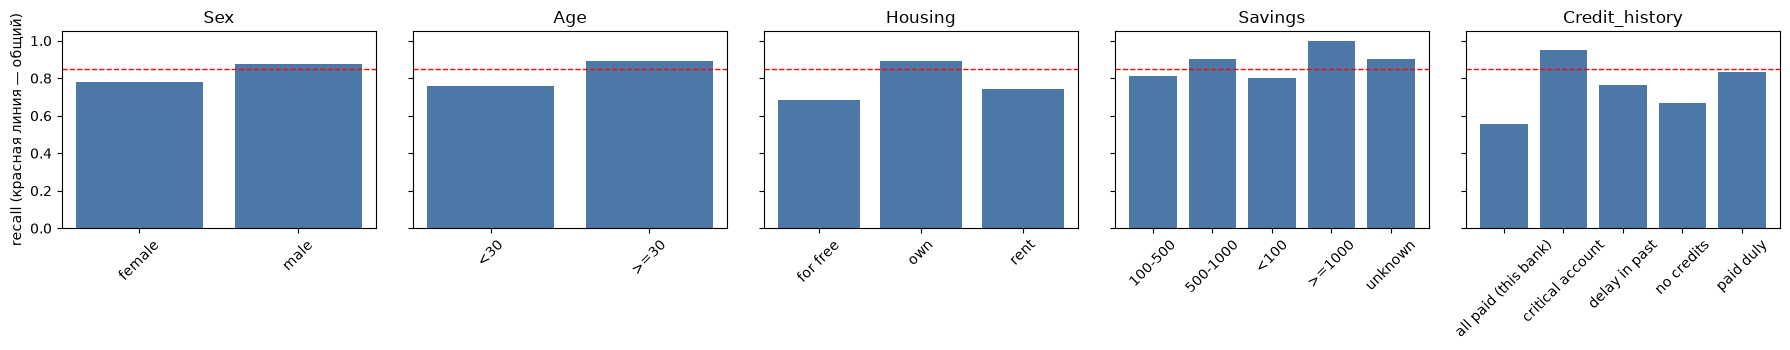

In [6]:
t = tests["Logistic Regression"]
fig, axes = plt.subplots(1, len(FEATURES), figsize=(18, 3.6), sharey=True)
for ax, f in zip(axes, FEATURES):
    g = by_group(t, f)
    ax.bar(g.index, g.recall, color="#4C78A8"); ax.axhline(recall_score(t.good, t.pred), color="red", ls="--", lw=1)
    ax.set_title(f); ax.tick_params(axis="x", rotation=45); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("recall (красная линия — общий)")
plt.tight_layout(); plt.show()

## 4. Ответы на вопросы

*Цифры ниже — для Logistic Regression на тестовой выборке (300 клиентов). У Random Forest картина похожая, но он одобряет ~85 % клиентов, поэтому у него выше recall и выше FPR (ошибочно одобряются плохие заёмщики).*

**1. Различается ли качество модели между группами?** Да, по всем признакам.

| Признак | Группа с лучшими метриками | Группа с худшими метриками |
|---|---|---|
| Sex | male: accuracy 0.76, recall 0.88 | female: accuracy 0.70, recall 0.78 |
| Age | ≥30: accuracy 0.78, recall 0.89 | <30: accuracy 0.67, recall 0.76 |
| Housing | own: recall 0.89, approval 82 % | for free: recall 0.68, approval 47 %; rent: recall 0.74 |
| Savings | ≥500 / unknown: recall 0.90–1.0 | <100 и 100–500: recall 0.80–0.81 |
| Credit history | critical account: recall 0.95 | all paid (this bank): recall 0.56, approval 38 % |

**2. Какие группы стабильно получают худшие предсказания?** Женщины, клиенты младше 30, живущие «бесплатно» или в аренде, с малыми накоплениями и с кредитной историей «all paid (this bank)». У всех этих групп ниже recall и approval rate: модель чаще отказывает хорошим заёмщикам. Это видно и на графике — у этих групп столбцы заметно ниже красной линии (общего recall).

**3. Показывают ли прокси-признаки больше bias, чем Sex/Age?** Да. Разрыв по approval rate: Sex — 12 п.п., Age — 14 п.п., а Housing — 35 п.п., Credit history — 56 п.п. Разрыв по recall: Sex — 10 п.п., Age — 14 п.п., Credit history — 40 п.п. Если проверить только Sex и Age, мы увидим лишь меньшую часть проблемы. Заметна и обратная сторона: клиентов с `critical account` и с накоплениями 500–1000 модель одобряет слишком охотно — FPR 0.88 и 1.0, то есть почти всем плохим заёмщикам из этих групп кредит одобрен.

**4. Почему возникают такие различия?**
- В данных у этих групп разная доля хороших заёмщиков (например, у молодых ~64 % против ~74 %), и модель выучивает «группа = риск».
- Housing, Savings и Credit history связаны с возрастом, доходом и социальным положением, поэтому работают как косвенные признаки (прокси) для Age и Sex.
- Многие группы маленькие (в тесте 11–34 человека), по ним модель учится хуже, а оценки шумные.
- Датасет исторический: он отражает прошлые решения банка, а не «объективный» риск.
- Модель оптимизирует общую accuracy, и небольшие группы «жертвуются» ради среднего значения.

**5. Почему это критично для кредитного скоринга?**
- Отказ хорошему клиенту — это недоступный кредит на жильё, учёбу или бизнес, и такие ошибки систематически накапливаются у одних и тех же групп.
- Дискриминация по полу и возрасту, в том числе косвенная через прокси-признаки, запрещена законом; убрать столбец `Sex` недостаточно.
- Для банка это и упущенная прибыль (отказы хорошим клиентам), и реальные убытки (ложные одобрения), и репутационный риск.
- Общая accuracy 0.74 выглядит приемлемо, но внутри групп метрики различаются на 10–40 п.п., и без проверки по группам этого не видно.

**Ограничение:** тест небольшой (300 клиентов), поэтому цифры по малым группам приблизительные; для надёжных выводов нужна кросс-валидация или больше данных. В продакшене стоит мониторить метрики по группам и задавать допустимый разрыв.
